# 02 – Cost structure and mix effect (Branch 2 continued + Branch 3)

**Hypotheses:**
> **H2 (Branch 2):** Part of the decline in the energy share after 2022 comes from lower energy prices (expected to bring the share back to the pre-crisis level of 33–36%), and the part below that level comes from the green transformation (alternative fuels, solar, waste heat) and portfolio changes. Test: price-volume decomposition, energy consumption per ton, mix effect.

> **H3 (Branch 3):** The new businesses (international white cement, building materials) did not raise the overall gross margin, but made revenue more FX-denominated and less volatile. Test: segment margins and mix effect; margin volatility before and after the transformation.

**Result carried over from notebook 01 (H2, price side):** Çimsa's implied energy price rose much less than the market in 2022 and fell less than the market after 2023. It tracks the market with a lag and in a smoothed way, and there is no lasting, company-specific advantage on the price side. In 2025 the implied price is still ~1.6 times that of 2020, yet the share of energy in production cost (21%) is clearly below the pre-crisis 33–36% band. The question of this notebook is therefore: **Why did the energy share fall below this band?** Did the numerator (energy cost) shrink, or did the denominator (non-energy costs, new businesses) grow?

**Data:** Only `output/tables/annual_master.csv` and `output/tables/cpi_monthly.csv`. Default view `view = own`. Each comparison is made within the same series (basis): nominal (2016–2022) and IAS 29 (the 2023-report version of 2022 – 2025).

## Setup: loading data and helpers

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "output" / "tables"
FIGS = ROOT / "output" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# Colours (same fixed order as in 01)
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
C_GREY, C_INK, C_MUTED = "#8a8985", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "lines.linewidth": 2, "legend.frameon": False,
})

In [2]:
master = pd.read_csv(TABLES / "annual_master.csv")
cpi = pd.read_csv(TABLES / "cpi_monthly.csv")
own = master[(master["view"] == "own") & master["year"].between(2016, 2025)].set_index("year").sort_index()

def row(year, view):
    r = master[(master["year"] == year) & (master["view"] == view)]
    assert len(r) == 1, (year, view)
    return r.iloc[0]

r2022 = row(2022, "restated_in_2023")   # start of the IAS 29 series (SBS included)
r2019 = row(2019, "restated_in_2020")   # 2019 excluding international white cement
print(f"own rows: {len(own)}; 2022 restated basis: {r2022['basis']}; 2019 restated basis: {r2019['basis']}")

own rows: 10; 2022 restated basis: tms29; 2019 restated basis: nominal


## 1. Cost structure (2016–2025)

Breakdown of total production cost into five items (own reports). There are two bars for 2022: the own report (nominal) and the 2023-report version (IAS 29 + SBS). The dashed line between them marks the accounting change.

**Changes in item definitions:**
- **Direct labour** was redefined in 2016 and does not represent the true total labour cost.
- The **raw material / other production** split changed in 2020 and 2022. For example, 2021 raw material is TRY 341 million in its own report and TRY 887 million in the 2022 report. The two items should be read together over time.
- **Energy:** the 2025 report moved ~TRY 1.1 billion of 2024 energy cost to "other production". The 2025 energy share uses the new classification, 2024 and earlier the old one.
- **2016:** The note has a sixth line (impairment, TRY 7.25 million); the sum of the five items falls short by this amount.

In [3]:
ITEMS = {"energy_cost": ("Energy", C_ORANGE), "raw_material": ("Raw material", C_BLUE),
         "other_production": ("Other production", C_AQUA), "direct_labor": ("Direct labour", C_YELLOW),
         "depreciation": ("Depreciation", C_MAGENTA)}

def shares(r):
    return pd.Series({k: r[k] / r["total_production_cost"] for k in ITEMS})

cols = {str(y): shares(own.loc[y]) for y in range(2016, 2023)}
cols["2022\n(IAS 29)"] = shares(r2022)
cols.update({str(y): shares(own.loc[y]) for y in range(2023, 2026)})
cost_shares = pd.DataFrame(cols).T
(cost_shares * 100).round(1)

,energy_cost,raw_material,other_production,direct_labor,depreciation
2016,33.2,29.3,22.6,7.0,7.0
2017,33.1,38.2,15.2,6.0,7.5
2018,36.4,39.2,10.5,5.6,8.3
2019,36.4,37.3,10.3,6.2,9.9
2020,46.7,22.2,16.8,6.6,7.7
2021,50.7,12.4,28.5,4.2,4.2
2022,59.6,25.6,9.6,3.2,2.1
2022\n(IAS 29),52.6,27.4,10.4,4.0,5.7
2023,40.6,29.2,17.2,5.6,7.4
2024,29.9,37.2,18.1,6.9,7.9


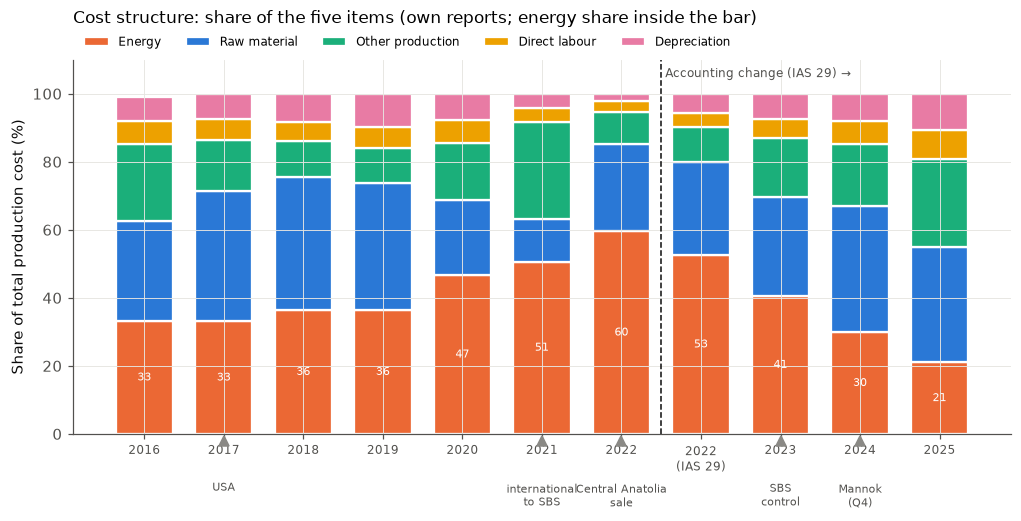

In [4]:
SCOPE_NOTES = {"2017": "USA", "2021": "international\nto SBS", "2022": "Central Anatolia\nsale",
               "2023": "SBS\ncontrol", "2024": "Mannok\n(Q4)"}

fig, ax = plt.subplots(figsize=(11, 5.4))
x = np.arange(len(cost_shares))
bottom = np.zeros(len(cost_shares))
for k, (lab, c) in ITEMS.items():
    vals = cost_shares[k].values * 100
    ax.bar(x, vals, bottom=bottom, color=c, width=0.72, edgecolor="white", linewidth=1.5, label=lab)
    for xi, v, b in zip(x, vals, bottom):
        if k == "energy_cost":
            ax.text(xi, b + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color="white")
    bottom += vals
i_tms = list(cost_shares.index).index("2022\n(IAS 29)")
ax.axvline(i_tms - 0.5, color=C_INK, linestyle="--", linewidth=1)
ax.text(i_tms - 0.45, 104, "Accounting change (IAS 29) →", fontsize=8, color=C_MUTED, va="bottom")
for lab, note in SCOPE_NOTES.items():
    i = list(cost_shares.index).index(lab)
    ax.plot(i, -0.02, marker="^", markersize=7, color=C_GREY, transform=ax.get_xaxis_transform(), clip_on=False)
    ax.text(i, -0.13, note, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=7, color=C_MUTED)
ax.set_xticks(x)
ax.set_xticklabels(cost_shares.index, fontsize=8)
ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 20))
ax.set_ylabel("Share of total production cost (%)")
ax.set_title("Cost structure: share of the five items (own reports; energy share inside the bar)", loc="left", fontsize=11, pad=24)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=5, fontsize=8)
fig.subplots_adjust(bottom=0.25)
fig.savefig(FIGS / "02_cost_structure_shares.png", bbox_inches="tight")
plt.show()

**What we see:** The energy share is 33–36% in 2016–2019, 47–60% in 2020–2022 and 41% → 21% in 2023–2025. After 2023, as the share of energy shrinks, the shares of raw material and other production costs grow. In 2025 energy (21%) is behind raw material (34%) and other production (26%).

## 2. Energy share decomposition (did the numerator shrink or the denominator grow?)

Energy share = E / T (E: energy cost, T: total production cost). Log-change decomposition:

**Δln(share) = Δln(E) − Δln(T)**

There are two parts: the change in energy cost itself and the change in total cost (denominator effect). We also split the denominator into items. Each item's contribution to Δln(T) = (change in the item / change in T) × Δln(T); the contributions add up exactly to Δln(T). Hence:

**Δln(share) = [Δln(E) − E's contribution to Δln(T)] − Σ (contributions of the non-energy items to Δln(T))**

- The first term is the **"energy side"**: the change in the share relative to a case in which energy cost had not changed.
- The second term is the **"non-energy side" (denominator effect)**: the change in the share relative to a case in which non-energy costs had not changed.

**Periods (each within the same series):**
- **a) 2022 → 2025 (IAS 29):** The starting point is the 2023-report version of 2022 (SBS included). Because the two reports are in different year-end purchasing power, the 2022 amounts are rolled forward to December 2025 purchasing power with the CPI (December 2025 / December 2023 CPI).
- **b) 2019 → 2022 (nominal):** The starting point is the 2020-report version of 2019 (excluding international white cement; consistent with the 2020–2022 scope). So that item changes can be read in real terms, the 2019 amounts are rolled forward to 2022 prices with the annual average CPI ratio.

The CPI adjustment affects numerator and denominator by the same ratio, so it does not change Δln(share); it only makes the components readable in real terms.

In [5]:
COST_ITEMS = ["energy_cost", "raw_material", "other_production", "direct_labor", "depreciation"]
cpi_val = lambda y, m: cpi[(cpi["year"] == y) & (cpi["period"] == m)]["value"].iloc[0]
cpi_avg = lambda y: cpi[cpi["year"] == y]["value"].mean()

def share_decomposition(a, b, deflator):
    """a: start row, b: end row; deflator: factor that rolls a's amounts forward to b's purchasing power."""
    T0, T1 = a["total_production_cost"] * deflator, b["total_production_cost"]
    E0, E1 = a["energy_cost"] * deflator, b["energy_cost"]
    dlnT = np.log(T1 / T0)
    rows = {}
    for k in COST_ITEMS:
        d = b[k] - a[k] * deflator
        rows[k] = {"start_mn_try": a[k] * deflator / 1e6, "end_mn_try": b[k] / 1e6, "change_mn_try": d / 1e6,
                   "real_change_pct": (b[k] / (a[k] * deflator) - 1) * 100,
                   "contrib_to_dlnT": d / (T1 - T0) * dlnT}
    items = pd.DataFrame(rows).T
    # the sum of the five items may not match T exactly (the 2016 case); the difference is a separate row
    resid = dlnT - items["contrib_to_dlnT"].sum()
    summary = pd.Series({
        "share_start": E0 / T0, "share_end": E1 / T1,
        "dln_share": np.log((E1 / T1) / (E0 / T0)),
        "dln_energy": np.log(E1 / E0), "minus_dln_total": -dlnT,
        "energy_side": np.log(E1 / E0) - items.loc["energy_cost", "contrib_to_dlnT"],
        "non_energy_side": -(items.drop("energy_cost")["contrib_to_dlnT"].sum() + resid),
        "residual_items_vs_total": resid, "deflator": deflator,
    })
    assert np.isclose(summary["energy_side"] + summary["non_energy_side"], summary["dln_share"])
    assert np.isclose(summary["dln_energy"] + summary["minus_dln_total"], summary["dln_share"])
    return summary, items

PERIODS = {
    "a) 2022→2025 (IAS 29)": (r2022, own.loc[2025], cpi_val(2025, "M12") / cpi_val(2023, "M12")),
    "b) 2019→2022 (nominal)": (r2019, own.loc[2022], cpi_avg(2022) / cpi_avg(2019)),
}
dec = {p: share_decomposition(*args) for p, args in PERIODS.items()}
pd.DataFrame({p: s for p, (s, _) in dec.items()}).round(3)

,a) 2022→2025 (IAS 29),b) 2019→2022 (nominal)
share_start,0.526,0.473
share_end,0.210,0.596
dln_share,-0.916,0.230
dln_energy,-0.725,0.995
minus_dln_total,-0.191,-0.765
energy_side,-0.479,0.457
non_energy_side,-0.437,-0.228
residual_items_vs_total,0.000,0.000
deflator,1.890,2.314


Item-level detail: start and end amounts rolled to the same purchasing power with the CPI (TRY million), real change (%) and contribution to Δln(T). If a non-energy item's contribution is positive, the denominator has grown and the energy share has been pushed down.

In [6]:
item_tables = pd.concat({p: items for p, (_, items) in dec.items()})
item_tables.round(3)

start_mn_try  end_mn_try  change_mn_try  real_change_pct  contrib_to_dlnT
a) 2022→2025 (IAS 29)  energy_cost          14875.483    7207.512      -7667.971          -51.548           -0.246
                       raw_material          7742.476   11650.239       3907.763           50.472            0.125
                       other_production      2933.047    8810.941       5877.894          200.402            0.189
                       direct_labor          1123.776    2956.549       1832.773          163.091            0.059
                       depreciation          1611.138    3624.737       2013.599          124.980            0.065
b) 2019→2022 (nominal) energy_cost           1343.518    3632.105       2288.587          170.343            0.537
                       raw_material           518.993    1558.255       1039.262          200.246            0.244
                       other_production       489.490     584.286         94.796           19.366            0.022
                       direct_labor           198.373     193.099         -5.274           -2.659           -0.001
                       depreciation           287.174     129.404       -157.770          -54.939           -0.037

In [7]:
# Raw material + other production together (a more robust reading given the definition changes)
pd.DataFrame({p: {"raw_plus_other_contrib_to_dlnT": items.loc[["raw_material", "other_production"], "contrib_to_dlnT"].sum(),
                  "raw_plus_other_real_change_pct": (items.loc[["raw_material", "other_production"], "end_mn_try"].sum()
                                                     / items.loc[["raw_material", "other_production"], "start_mn_try"].sum() - 1) * 100}
              for p, (_, items) in dec.items()}).round(3)

,a) 2022→2025 (IAS 29),b) 2019→2022 (nominal)
raw_plus_other_contrib_to_dlnT,0.314,0.266
raw_plus_other_real_change_pct,91.664,112.452


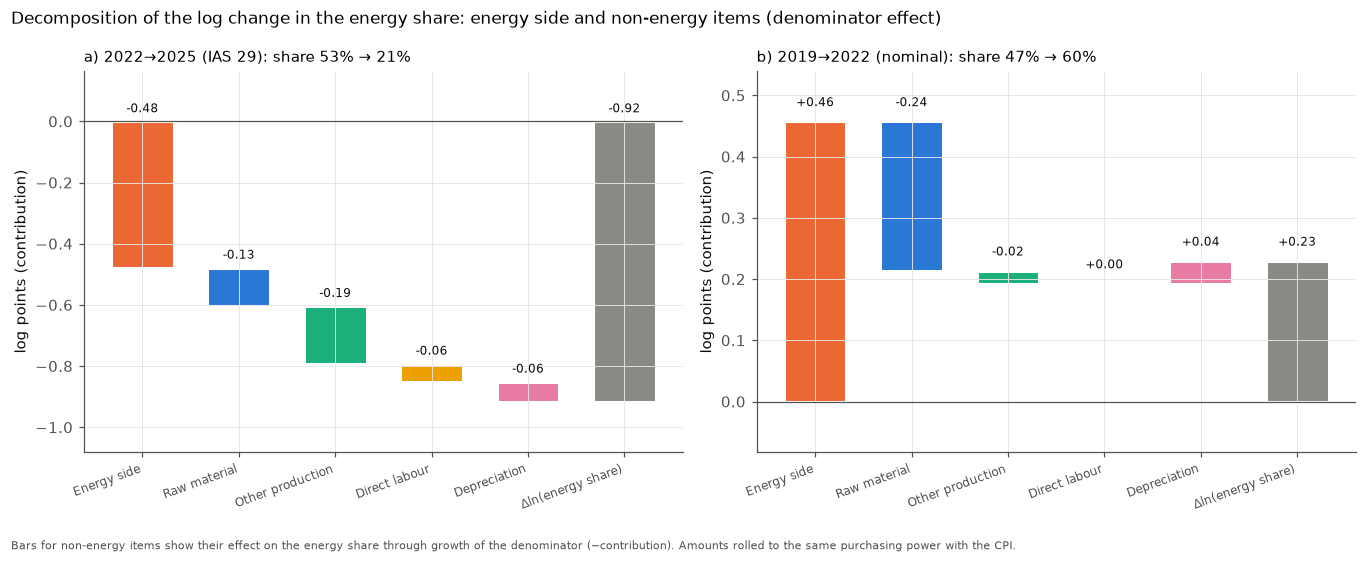

In [8]:
def waterfall_ylim(ax, steps, total, pad_frac=0.18):
    # keep all cumulative levels and the total visible; leave room for the labels
    lv = np.concatenate([[0], np.cumsum(steps), [total]])
    lo, hi = min(lv.min(), 0), max(lv.max(), 0)
    pad = (hi - lo) * pad_frac
    ax.set_ylim(lo - pad, hi + pad)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
LABELS = {"energy_side": "Energy side", "raw_material": "Raw material", "other_production": "Other production",
          "direct_labor": "Direct labour", "depreciation": "Depreciation", "dln_share": "Δln(energy share)"}
for ax, (p, (s, items)) in zip(axes, dec.items()):
    vals = [s["energy_side"]] + [-items.loc[k, "contrib_to_dlnT"] for k in ["raw_material", "other_production", "direct_labor", "depreciation"]]
    names = ["energy_side", "raw_material", "other_production", "direct_labor", "depreciation"]
    colors = [C_ORANGE, C_BLUE, C_AQUA, C_YELLOW, C_MAGENTA]
    level = 0.0
    for i, (n, v, c) in enumerate(zip(names, vals, colors)):
        ax.bar(i, v, bottom=level, color=c, width=0.65, edgecolor="white", linewidth=2)
        ax.text(i, level + max(v, 0) + 0.02, f"{v:+.2f}", ha="center", va="bottom", fontsize=8, color=C_INK)
        level += v
    waterfall_ylim(ax, vals, s["dln_share"])
    resid = -s["residual_items_vs_total"]
    total = s["dln_share"]
    ax.bar(len(names), total, color=C_GREY, width=0.65, edgecolor="white", linewidth=2)
    ax.text(len(names), max(total, 0) + 0.02, f"{total:+.2f}", ha="center", va="bottom", fontsize=8, color=C_INK)
    ax.axhline(0, color=C_MUTED, linewidth=0.8)
    ax.set_xticks(range(len(names) + 1))
    ax.set_xticklabels([LABELS[n] for n in names] + [LABELS["dln_share"]], fontsize=8, rotation=20, ha="right")
    ax.set_title(f"{p}: share {s['share_start']*100:.0f}% → {s['share_end']*100:.0f}%", loc="left", fontsize=10)
axes[0].set_ylabel("log points (contribution)")
axes[1].set_ylabel("log points (contribution)")
fig.suptitle("Decomposition of the log change in the energy share: energy side and non-energy items (denominator effect)", x=0.01, ha="left", fontsize=11)
fig.text(0.01, -0.04, "Bars for non-energy items show their effect on the energy share through growth of the denominator (−contribution). "
         "Amounts rolled to the same purchasing power with the CPI.", fontsize=7.5, color=C_MUTED)
fig.tight_layout()
fig.savefig(FIGS / "02_energy_share_decomposition.png", bbox_inches="tight")
plt.show()

**Reclassification check (2024 in two reports).** The 2025 report moved part of 2024 energy cost to "other production". By comparing the two versions of the same year (2024) we can measure the effect of this transfer on the energy share. Total cost changes between the two reports by the CPI ratio; energy changes less.

In [9]:
a, b = own.loc[2024], row(2024, "restated_in_2025")
infl = cpi_val(2025, "M12") / cpi_val(2024, "M12")
reclass = pd.Series({
    "share_2024_own_report": a["energy_share_production_cost"],
    "share_2024_in_2025_report": b["energy_share_production_cost"],
    "total_cost_ratio": b["total_production_cost"] / a["total_production_cost"],
    "cpi_ratio_dec25_dec24": infl,
    "energy_kept_ratio": (b["energy_cost"] / a["energy_cost"]) / infl,
    "moved_to_other_mn_try_2025pp": (a["energy_cost"] * infl - b["energy_cost"]) / 1e6,
    "dln_share_due_to_reclass": np.log(b["energy_share_production_cost"] / a["energy_share_production_cost"]),
})
reclass.round(4)

share_2024_own_report              0.2989
share_2024_in_2025_report          0.2585
total_cost_ratio                   1.3089
cpi_ratio_dec25_dec24              1.3089
energy_kept_ratio                  0.8649
moved_to_other_mn_try_2025pp    1108.7872
dln_share_due_to_reclass          -0.1452
dtype: float64

**What we see:**
- **a) 2022 → 2025:** The energy share goes from 53% to 21% (Δln = −0.92). About half of this is on the energy side: energy cost fell by ~52% in real terms. The other half is on the non-energy side: raw material, other production, depreciation and labour rose in real terms and enlarged the denominator. The largest denominator contributions come from other production and raw material.
- **Reclassification:** Comparing the two versions of 2024 shows that the 2025 classification shifted ~13.5% of energy cost to "other production". On its own this lowers the share by ~4 points (Δln ≈ −0.15). ~16% of the 2022 → 2025 log decline may be related to this definitional difference. The transfer ratio in 2025 is assumed to be the same as in 2024; the old-classification version of 2025 is not available in the reports.
- **b) 2019 → 2022:** The energy share goes from 47% to 60%. The increase is on the energy side (energy cost up ~170% in real terms). The real increase in raw material offset part of this increase by enlarging the denominator. Because the raw material/other split was redefined in 2022 and the Central Anatolia plants were sold mid-year, the item-level reading needs care.

## 3. Physical energy intensity (MWh/ton of cement and MWh/ton of clinker)

Total energy consumption (MWh) is available only for 2020–2025. The definition of cement production changes over the years:
- **2020–2023:** sum of grey + white + CAC (the report's total or its components).
- **2023 (own report):** Total 6.79 million tons; the white cement value (2.91) is inconsistent with other years and is flagged `suspect`. For comparison, the 2023 value in the 2024 report (5.22 million tons) is shown with a hollow marker.
- **2024–2025:** The reports only give total cement, with the footnote **"clinker included"**. The 2025 production table **excludes Mannok**. Whether total energy consumption covers Mannok is unclear line by line in 2025; in its own 2024 report it does not.

Because the numerator (total energy) also includes the energy of activities other than clinker and cement, these ratios are group-wide intensity indicators.

In [10]:
phys = pd.DataFrame({
    "total_energy_mwh": own["total_energy_consumption"],
    "cement_production_t": own["cement_production_total"],
    "clinker_production_t": own["clinker_production"],
}).loc[2020:2025]
phys["mwh_per_t_cement"] = phys["total_energy_mwh"] / phys["cement_production_t"]
phys["mwh_per_t_clinker"] = phys["total_energy_mwh"] / phys["clinker_production_t"]
phys["quality_flags"] = own.loc[2020:2025, "esg_quality_flags"]
r2023_alt = row(2023, "restated_in_2024")
alt_2023 = {"mwh_per_t_cement": r2023_alt["total_energy_consumption"] / r2023_alt["cement_production_total"],
            "mwh_per_t_clinker": r2023_alt["total_energy_consumption"] / r2023_alt["clinker_production"]}
print("2023 alternative (production in the 2024 report):", {k: round(v, 3) for k, v in alt_2023.items()})
phys.round(3)

2023 alternative (production in the 2024 report): {'mwh_per_t_cement': np.float64(1.217), 'mwh_per_t_clinker': np.float64(1.188)}


,total_energy_mwh,cement_production_t,clinker_production_t,mwh_per_t_cement,mwh_per_t_clinker,quality_flags
year,,,,,,
2020,7135186.0,5639000.0,6400000.0,1.265,1.115,NaN
2021,7669074.0,5635700.0,6920000.0,1.361,1.108,NaN
2022,6439517.0,4791430.0,5860000.0,1.344,1.099,NaN
2023,6353919.0,6792660.0,4970000.0,0.935,1.278,cement_production_total=suspect; white_cement_...
2024,6360983.0,5310000.0,5464870.0,1.198,1.164,thermal_energy_conventional=unit_corrected
2025,7188725.0,6800000.0,6240000.0,1.057,1.152,NaN


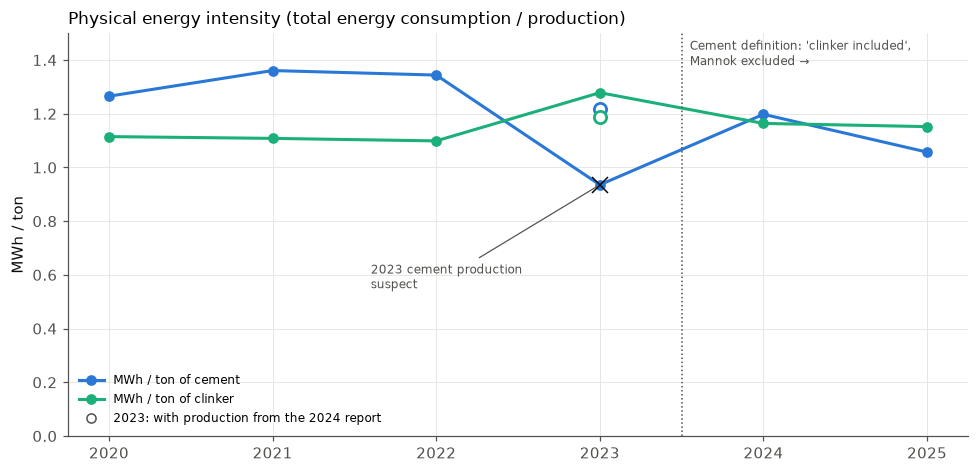

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for col, lab, c in [("mwh_per_t_cement", "MWh / ton of cement", C_BLUE), ("mwh_per_t_clinker", "MWh / ton of clinker", C_AQUA)]:
    ax.plot(phys.index, phys[col], marker="o", color=c, label=lab)
    ax.plot(2023, alt_2023[col], marker="o", markersize=8, markerfacecolor="white", markeredgecolor=c,
            markeredgewidth=1.8, linestyle="none")
ax.plot(2023, phys.loc[2023, "mwh_per_t_cement"], marker="x", markersize=10, color=C_INK, linestyle="none")
ax.annotate("2023 cement production\nsuspect", (2023, phys.loc[2023, "mwh_per_t_cement"]), xytext=(2021.6, 0.55),
            fontsize=8, color=C_MUTED, arrowprops=dict(arrowstyle="-", color=C_MUTED, linewidth=0.8))
ax.axvline(2023.5, color=C_MUTED, linestyle=":", linewidth=1)
ax.text(2023.55, 1.48, "Cement definition: 'clinker included',\nMannok excluded →", fontsize=8, color=C_MUTED, va="top")
ax.set_ylim(0, 1.5)
ax.set_xticks(phys.index)
ax.set_ylabel("MWh / ton")
ax.set_title("Physical energy intensity (total energy consumption / production)", loc="left", fontsize=11)
ax.legend(handles=[Line2D([], [], color=C_BLUE, marker="o", label="MWh / ton of cement"),
                   Line2D([], [], color=C_AQUA, marker="o", label="MWh / ton of clinker"),
                   Line2D([], [], color=C_MUTED, marker="o", markerfacecolor="white", linestyle="none",
                          label="2023: with production from the 2024 report")], loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "02_physical_energy_intensity.png", bbox_inches="tight")
plt.show()

**What we see:** Energy per ton of cement is 1.27–1.36 MWh in 2020–2022, 1.20 in 2024 and 1.06 MWh in 2025. Energy per ton of clinker is in the 1.10–1.28 range with no clear trend. The decline in the cement-based indicator coincides with the definition change in 2024 ("clinker included"). In 2025 production excludes Mannok while the energy scope is unclear. Therefore a lasting improvement in physical efficiency cannot be shown with this data.

## 4. Segments and mix effect (H3)

### 4a. Segment revenue shares and gross margins (2016–2025)

- **Denominator of the revenue share:** Sum of operating segments before elimination (cement + ready-mix concrete + building materials; annual_master_dictionary).
- **Eliminations:** The 2016–2019 reports have an inter-segment elimination line (negative in revenue, 0 in gross profit). Reports after 2020 do not have this line.
- **Building materials:** Reported from 2024 (Mannok; only Q4 in 2024).
- **Scope:** The 2023-report version of 2022 includes SBS (international white cement) within the cement segment; SBS is not reported as a separate segment.

In [12]:
SEGS = {"cement": ("Cement", C_BLUE), "readymix": ("Ready-mix concrete", C_AQUA), "building_materials": ("Building materials", C_ORANGE)}

def seg_frame(r):
    rev = {s: (0.0 if pd.isna(r[f"segment_{s}_revenue"]) else r[f"segment_{s}_revenue"]) for s in SEGS}
    gp = {s: (0.0 if pd.isna(r[f"segment_{s}_gross_profit"]) else r[f"segment_{s}_gross_profit"]) for s in SEGS}
    R = sum(rev.values())
    return pd.DataFrame({"revenue": rev, "gross_profit": gp,
                         "weight": {s: rev[s] / R for s in SEGS},
                         "margin": {s: (gp[s] / rev[s] if rev[s] else np.nan) for s in SEGS}})

seg_rows = {}
for y in range(2016, 2026):
    f = seg_frame(own.loc[y])
    seg_rows[str(y)] = pd.concat([f["weight"].add_prefix("share_"), f["margin"].add_prefix("margin_")])
f = seg_frame(r2022)
seg_rows["2022 (IAS 29)"] = pd.concat([f["weight"].add_prefix("share_"), f["margin"].add_prefix("margin_")])
seg_tbl = pd.DataFrame(seg_rows).T
seg_tbl["elimination_revenue_mn_try"] = [own.loc[int(i), "segment_elimination_revenue"] / 1e6 if i.isdigit() else np.nan for i in seg_tbl.index]
(seg_tbl * pd.Series({c: (100 if c.startswith(("share", "margin")) else 1) for c in seg_tbl.columns})).round(1)

,share_cement,share_readymix,share_building_materials,margin_cement,margin_readymix,margin_building_materials,elimination_revenue_mn_try
2016,78.4,21.6,0.0,39.2,-2.5,NaN,-72.2
2017,79.8,20.2,0.0,32.6,-4.8,NaN,-84.3
2018,82.1,17.9,0.0,28.6,-2.6,NaN,-64.9
2019,90.7,9.3,0.0,13.2,29.5,NaN,-339.1
2020,86.7,13.3,0.0,25.8,1.2,NaN,NaN
2021,88.7,11.3,0.0,20.1,11.1,NaN,NaN
2022,87.5,12.5,0.0,18.2,10.7,NaN,NaN
2023,86.4,13.6,0.0,20.4,15.1,NaN,NaN
2024,76.4,19.0,4.6,23.1,16.5,15.5,NaN
2025,68.6,11.7,19.8,21.3,17.2,15.1,NaN


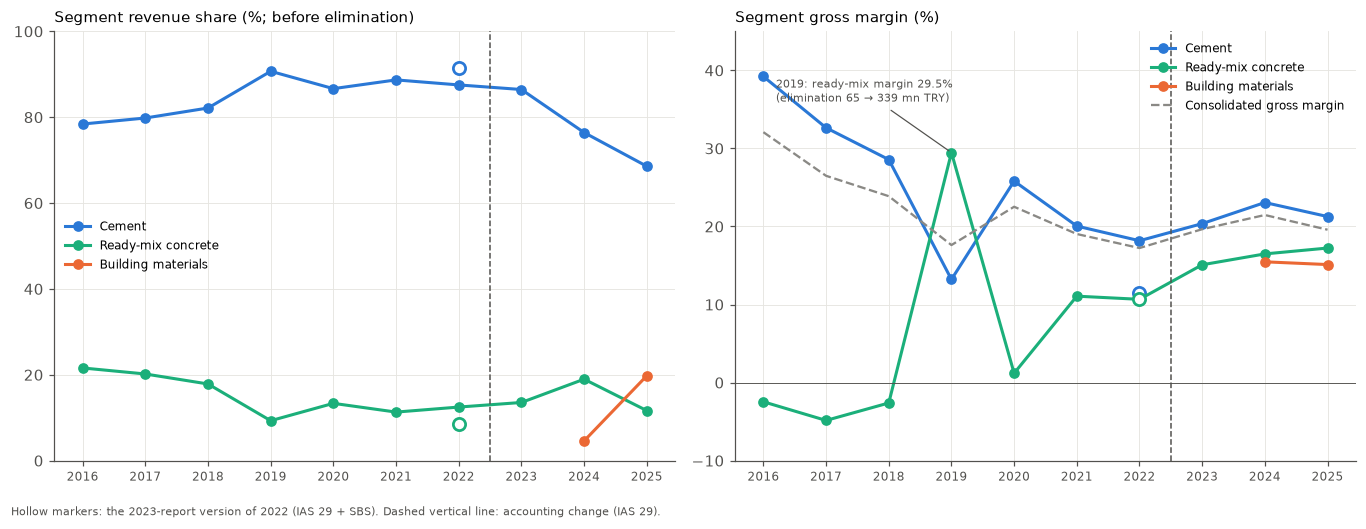

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
yrs = list(range(2016, 2026))
for s, (lab, c) in SEGS.items():
    sh = [seg_tbl.loc[str(y), f"share_{s}"] * 100 if own.loc[y, f"segment_{s}_revenue"] > 0 else np.nan for y in yrs]
    mg = [seg_tbl.loc[str(y), f"margin_{s}"] * 100 for y in yrs]
    axes[0].plot(yrs, sh, marker="o", color=c, label=lab)
    axes[1].plot(yrs, mg, marker="o", color=c, label=lab)
    if s != "building_materials":
        axes[0].plot(2022, seg_tbl.loc["2022 (IAS 29)", f"share_{s}"] * 100, marker="o", markersize=8,
                 markerfacecolor="white", markeredgecolor=c, markeredgewidth=1.8, linestyle="none")
    axes[1].plot(2022, seg_tbl.loc["2022 (IAS 29)", f"margin_{s}"] * 100, marker="o", markersize=8,
                 markerfacecolor="white", markeredgecolor=c, markeredgewidth=1.8, linestyle="none")
axes[1].plot(yrs, own["gross_margin"] * 100, color=C_GREY, linestyle="--", linewidth=1.5, label="Consolidated gross margin")
axes[1].annotate("2019: ready-mix margin 29.5%\n(elimination 65 → 339 mn TRY)", (2019, seg_tbl.loc["2019", "margin_readymix"] * 100),
                 xytext=(2016.2, 36), fontsize=7.5, color=C_MUTED, arrowprops=dict(arrowstyle="-", color=C_MUTED, linewidth=0.8))
axes[0].set_title("Segment revenue share (%; before elimination)", loc="left", fontsize=10)
axes[1].set_title("Segment gross margin (%)", loc="left", fontsize=10)
axes[0].set_ylim(0, 100); axes[1].set_ylim(-10, 45)
for ax in axes:
    ax.set_xticks(yrs); ax.tick_params(axis="x", labelsize=8)
    ax.axvline(2022.5, color=C_MUTED, linestyle="--", linewidth=1)
    ax.axhline(0, color=C_MUTED, linewidth=0.6)
axes[0].legend(loc="center left", fontsize=8)
axes[1].legend(loc="upper right", fontsize=8)
fig.text(0.01, -0.03, "Hollow markers: the 2023-report version of 2022 (IAS 29 + SBS). Dashed vertical line: accounting change (IAS 29).",
         fontsize=7.5, color=C_MUTED)
fig.tight_layout()
fig.savefig(FIGS / "02_segment_shares_margins.png", bbox_inches="tight")
plt.show()

**What we see:** Cement makes up most of revenue (78–92% in 2016–2023). In 2025 its share falls to 69%; building materials 20%, ready-mix concrete 12%. The cement margin falls from 39% in 2016 to the 13–26% range in 2019–2022 (11.5% in the IAS 29 version of 2022) and is 21% in 2025. Ready-mix concrete is loss-making in 2016–2018 (negative gross margin).

*Note:* In its own 2019 report the ready-mix margin is 29.5%. The 2020 report gives 3% for the same year. In the same report the inter-segment elimination rises from 65 to TRY 339 million. This may point to a change in inter-segment transfer pricing (not verified). The consolidated totals are consistent; only the cement/ready-mix split is affected.

### 4b. Shift-share: decomposing the change in the consolidated gross margin

Segment-weighted margin M = Σ wᵢ · mᵢ (w: revenue share, m: segment gross margin). The change is decomposed with midpoint (average) weights so that no interaction term remains:
- **Within-segment margin effect** = Σ avg(w) · Δm: the difference relative to a case in which the segments' own margins had not changed.
- **Mix (weight) effect** = Σ Δw · avg(m): the difference relative to a case in which segment weights had not changed.
- **New segment contribution (building materials):** This segment does not exist in 2022. First the 2025 weights of the existing segments are rescaled among themselves; the new segment's contribution = w₂₀₂₅(BM) × (m₂₀₂₅(BM) − weighted 2025 margin of the existing segments). If the building materials margin is below the average of the existing businesses, this term is negative.
- **Elimination effect (2016–2019):** The segment-weighted margin is computed on revenue before elimination. The consolidated margin is computed on revenue after elimination. Because elimination is 0 in gross profit, consolidated margin = segment margin × (revenue before / after elimination). This difference is shown as a separate term. Reports after 2020 have no elimination line; this term is 0.

Periods: **2022 (2023 report, IAS 29) → 2025** and **2016 → 2019** (nominal). Because ratios (share and margin) are not affected by purchasing power, ratios from different reports within the IAS 29 period can be compared. Because of the inter-segment transfer change in 2019, **2016 → 2018** is also shown as a sensitivity.

In [14]:
def shift_share(a, b, new_segments=()):
    fa, fb = seg_frame(a), seg_frame(b)
    existing = [s for s in SEGS if s not in new_segments and fa.loc[s, "revenue"] > 0]
    new = [s for s in new_segments if fb.loc[s, "revenue"] > 0]
    w0, m0 = fa.loc[existing, "weight"], fa.loc[existing, "margin"]
    s_exist = fb.loc[existing, "weight"].sum()
    v1, m1 = fb.loc[existing, "weight"] / s_exist, fb.loc[existing, "margin"]
    M0 = (w0 * m0).sum()
    M1_exist = (v1 * m1).sum()
    within = ((w0 + v1) / 2 * (m1 - m0))
    mix = ((v1 - w0) * (m0 + m1) / 2)
    M1 = (fb["weight"] * fb["margin"].fillna(0)).sum()
    new_contrib = M1 - M1_exist
    cons0, cons1 = a["gross_margin"], b["gross_margin"]
    elim = (cons1 - M1) - (cons0 - M0)
    out = {f"within_{s}": within[s] for s in existing}
    out.update({f"mix_{s}": mix[s] for s in existing})
    out.update({"within_total": within.sum(), "mix_total": mix.sum(), "new_segment": new_contrib,
                "elimination_effect": elim, "consolidated_margin_start": cons0, "consolidated_margin_end": cons1,
                "consolidated_change": cons1 - cons0})
    assert np.isclose(out["within_total"] + out["mix_total"] + new_contrib + elim, cons1 - cons0)
    return pd.Series(out)

SS_PERIODS = {
    "2022 (IAS 29) → 2025": (r2022, own.loc[2025], ("building_materials",)),
    "2022 (IAS 29) → 2024": (r2022, own.loc[2024], ("building_materials",)),
    "2016 → 2019 (nominal)": (own.loc[2016], own.loc[2019], ()),
    "2016 → 2018 (nominal, sensitivity)": (own.loc[2016], own.loc[2018], ()),
}
ss = pd.DataFrame({p: shift_share(*args) for p, args in SS_PERIODS.items()})
(ss * 100).round(2)  # percentage points

,2022 (IAS 29) → 2025,2022 (IAS 29) → 2024,2016 → 2019 (nominal),"2016 → 2018 (nominal, sensitivity)"
within_cement,8.64,9.92,-21.98,-8.54
within_readymix,0.76,0.83,4.93,-0.03
mix_cement,-0.99,-1.97,3.22,1.27
mix_readymix,0.84,1.55,-1.66,0.09
within_total,9.40,10.75,-17.05,-8.57
mix_total,-0.15,-0.42,1.56,1.36
new_segment,-1.10,-0.29,0.00,0.00
elimination_effect,0.00,0.00,1.03,-0.98
consolidated_margin_start,11.43,11.43,32.08,32.08
consolidated_margin_end,19.59,21.47,17.62,23.88


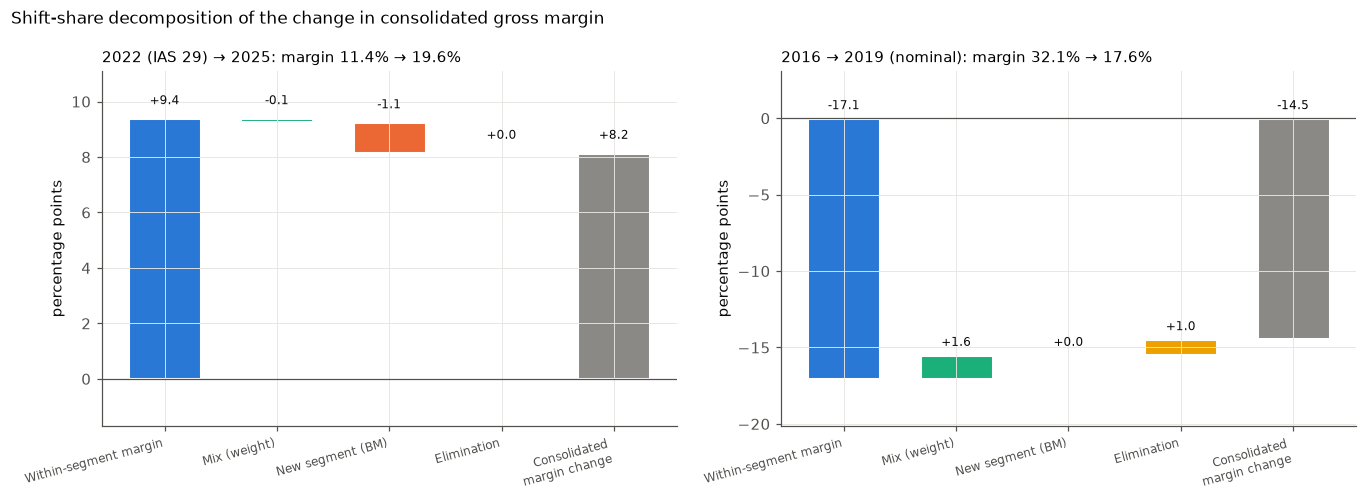

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
COMP = [("within_total", "Within-segment margin", C_BLUE), ("mix_total", "Mix (weight)", C_AQUA),
        ("new_segment", "New segment (BM)", C_ORANGE), ("elimination_effect", "Elimination", C_YELLOW)]
for ax, p in zip(axes, ["2022 (IAS 29) → 2025", "2016 → 2019 (nominal)"]):
    s = ss[p] * 100
    level = 0.0
    for i, (k, lab, c) in enumerate(COMP):
        v = s[k]
        ax.bar(i, v, bottom=level, color=c, width=0.65, edgecolor="white", linewidth=2)  # negative v is drawn downwards
        ax.text(i, level + max(v, 0) + 0.4, f"{v:+.1f}", ha="center", va="bottom", fontsize=8, color=C_INK)
        level += v
    waterfall_ylim(ax, [s[k] for k, _, _ in COMP], s["consolidated_change"])
    ax.bar(len(COMP), s["consolidated_change"], color=C_GREY, width=0.65, edgecolor="white", linewidth=2)
    ax.text(len(COMP), max(s["consolidated_change"], 0) + 0.4, f"{s['consolidated_change']:+.1f}", ha="center", va="bottom", fontsize=8)
    ax.axhline(0, color=C_MUTED, linewidth=0.8)
    ax.set_xticks(range(len(COMP) + 1))
    ax.set_xticklabels([c[1] for c in COMP] + ["Consolidated\nmargin change"], fontsize=8, rotation=15, ha="right")
    ax.set_title(f"{p}: margin {s['consolidated_margin_start']:.1f}% → {s['consolidated_margin_end']:.1f}%", loc="left", fontsize=10)
axes[0].set_ylabel("percentage points")
axes[1].set_ylabel("percentage points")
fig.suptitle("Shift-share decomposition of the change in consolidated gross margin", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIGS / "02_shift_share_gross_margin.png", bbox_inches="tight")
plt.show()

**What we see:**
- **2022 → 2025 (IAS 29):** Consolidated gross margin goes from 11.4% to 19.6% (+8.2 points). Almost all of the change comes together with the **within-segment margin** effect; most of it from the cement margin rising from 11.5% to 21.3%. The mix effect among existing segments is small and negative (the share of ready-mix concrete rose, and its margin is below cement's). **The contribution of building materials is negative (~−1.1 points):** its 2025 margin (15.1%) is below the weighted average of the existing businesses. Note that the starting year 2022 was a crisis year with an unusually low margin.
- **2016 → 2019 (nominal):** Margin goes from 32.1% to 17.6% (−14.5 points). The decline comes together with the within-segment margin effect (cement margin 39% → 13%). Because the inter-segment transfer change in 2019 affects the cement/ready-mix split, the 2016 → 2018 sensitivity should also be considered; in that period too the change is mainly within segments. The elimination term is small. The US white cement operation added in 2017 is within the cement segment, so it does not appear as a separate mix effect.

### 4c. Building materials (Mannok) compared with cement

In 2024 building materials cover only Q4 (from 1 October 2024); 2025 is the first full year. Amounts are consolidated (Çimsa's share in CBS is 68.31%).

In addition, we make a hypothetical bound calculation: if the cost of sales of the building materials segment is removed from total production cost and this segment's energy cost is taken as zero, what is the maximum energy share? Because the segment's actual energy cost is above zero, the true value is below this bound. Cost of sales and production cost are not the same concept; the calculation only gives an order of magnitude.

In [16]:
bm_rows = {}
for label, r in [("2024 (own report, Q4)", own.loc[2024]), ("2024 (2025 report)", row(2024, "restated_in_2025")),
                 ("2025 (own report)", own.loc[2025])]:
    f = seg_frame(r)
    bm_cos = r["segment_building_materials_cost_of_sales"]
    bm_rows[label] = {
        "bm_revenue_share": f.loc["building_materials", "weight"], "bm_margin": f.loc["building_materials", "margin"],
        "cement_margin": f.loc["cement", "margin"], "readymix_margin": f.loc["readymix", "margin"],
        "bm_cost_of_sales_mn_try": bm_cos / 1e6,
        "energy_share_reported": r["energy_share_production_cost"],
        "energy_share_upper_bound_ex_bm": r["energy_cost"] / (r["total_production_cost"] - bm_cos),
    }
bm = pd.DataFrame(bm_rows).T
# Extra assumption for 2025: the reclassification ratio is the same as in 2024 (energy_kept_ratio)
bm.loc["2025 (own report)", "energy_share_upper_bound_ex_bm_old_classification"] = (
    own.loc[2025, "energy_cost"] / reclass["energy_kept_ratio"]
    / (own.loc[2025, "total_production_cost"] - own.loc[2025, "segment_building_materials_cost_of_sales"]))
bm.round(3)

,bm_revenue_share,bm_margin,cement_margin,readymix_margin,bm_cost_of_sales_mn_try,energy_share_reported,energy_share_upper_bound_ex_bm,energy_share_upper_bound_ex_bm_old_classification
"2024 (own report, Q4)",0.046,0.155,0.231,0.165,1094.741,0.299,0.315,NaN
2024 (2025 report),0.046,0.155,0.231,0.165,1432.929,0.258,0.273,NaN
2025 (own report),0.198,0.151,0.213,0.172,7703.865,0.210,0.272,0.314


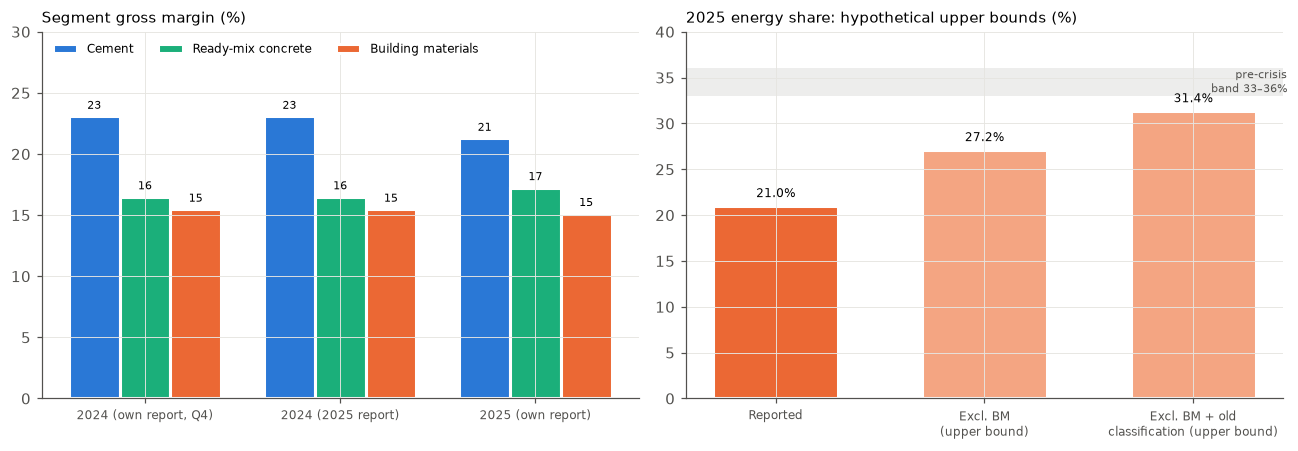

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
labels = list(bm.index)
x = np.arange(len(labels))
ax = axes[0]
wdt = 0.26
for j, (col, lab, c) in enumerate([("cement_margin", "Cement", C_BLUE), ("readymix_margin", "Ready-mix concrete", C_AQUA),
                                    ("bm_margin", "Building materials", C_ORANGE)]):
    ax.bar(x + (j - 1) * wdt, bm[col] * 100, width=wdt, color=c, edgecolor="white", linewidth=2, label=lab)
    for xi, v in zip(x, bm[col] * 100):
        ax.text(xi + (j - 1) * wdt, v + 0.4, f"{v:.0f}", ha="center", va="bottom", fontsize=7.5)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
ax.set_title("Segment gross margin (%)", loc="left", fontsize=10)
ax.set_ylim(0, 30)
ax.legend(loc="upper left", fontsize=8, ncol=3)

ax = axes[1]
y25 = "2025 (own report)"
vals = [bm.loc[y25, "energy_share_reported"], bm.loc[y25, "energy_share_upper_bound_ex_bm"],
        bm.loc[y25, "energy_share_upper_bound_ex_bm_old_classification"]]
names = ["Reported", "Excl. BM\n(upper bound)", "Excl. BM + old\nclassification (upper bound)"]
ax.bar(range(3), np.array(vals) * 100, color=[C_ORANGE, "#f4a582", "#f4a582"], width=0.6, edgecolor="white", linewidth=2)
for i, v in enumerate(vals):
    ax.text(i, v * 100 + 0.6, f"{v*100:.1f}%", ha="center", va="bottom", fontsize=8)
ax.axhspan(33, 36, color=C_GREY, alpha=0.15, linewidth=0)
ax.text(2.45, 34.5, "pre-crisis\nband 33–36%", fontsize=7.5, color=C_MUTED, va="center", ha="right")
ax.set_xticks(range(3)); ax.set_xticklabels(names, fontsize=8)
ax.set_ylim(0, 40)
ax.set_title("2025 energy share: hypothetical upper bounds (%)", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIGS / "02_building_materials_vs_cement.png", bbox_inches="tight")
plt.show()

**What we see:** In 2025 building materials account for ~20% of revenue. Its gross margin (15%) is below cement (21%) and ready-mix concrete (17%); similar in 2024 (15% – 16%). According to the hypothetical bound calculation:
- With the cost of building materials removed, the 2025 energy share is at most ~27%.
- If, in addition, the 2024 reclassification ratio is reversed, it is at most ~31%.

So the addition of building materials and the classification change come together with most of the 2025 share staying below the band (33–36%). The remaining 2–5 points may be related to factors such as the path of the energy price relative to 2016–2019, the real increase in raw material and other costs, and the scope of SBS, and cannot be separated with this data.

## 5. Interim findings and assessment of the hypotheses

**Section summaries**
1. **Cost structure:** The energy share fell from its 2022 peak (53–60%) to 21% in 2025; over the same period the shares of raw material and other production costs grew.
2. **Numerator or denominator:** About half of the log decline in the energy share from 2022 to 2025 comes together with the real decline in energy cost, and half with the real increase in non-energy costs (denominator effect). ~16% of the log decline may be related to the energy → other production reclassification in the 2025 report.
3. **Physical intensity:** No clear improvement in MWh/ton of clinker. The decline in MWh/ton of cement coincides with the definition change and the scope uncertainty.
4. **Mix:** The 2022 → 2025 increase in gross margin comes almost entirely together with higher within-segment margins (especially cement). The mix effect is small; the contribution of building materials is negative (~−1 point).
5. **Building materials:** Its margin is below cement's. The addition of this segment and the classification change come together with most of the energy share staying below the band (hypothetical upper-bound calculation).

**H2 – complete assessment: PARTIALLY**
- *Confirmed:* A significant part of the decline in the energy share after 2022 comes together with lower energy prices (01: price-volume decomposition and market index; 02: the energy side's ~half share of the log decline).
- *Not supported:* There is no trace linking the part below the band to the "green transformation". There is no lasting, company-specific advantage on the price side (01), and no lasting improvement in physical energy intensity can be shown (02, section 3).
- *Partially confirmed:* The "portfolio change" leg. The fall below the band comes mainly together with growth in non-energy costs (denominator effect), the consolidation of the less energy-intensive building materials segment and the reclassification in the 2025 report. The low share may reflect a broader cost base and a changed definition more than a decline in energy risk.

**H3 – margin part: CONFIRMED (preliminary assessment)**
- The new businesses do not appear to have raised the overall gross margin. The margin of building materials (2024–2025: 15%) is below cement's and its contribution in the shift-share is negative. The 2022 → 2025 margin increase comes together with higher own margins of the existing segments (especially cement).
- International white cement (SBS) is reported within the cement segment, so it cannot be measured as a separate mix effect. No assessment can be made for this part.
- **The other parts of H3:** The "more FX-denominated" part will be tested in notebook **03**, and the "less volatile" part in the synthesis notebook **04**.